# RETAIL IN SALES DATA ANALYSIS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("data.csv" ,  encoding = "latin1")
df.head()

In [3]:
df.shape

(541909, 8)

In [4]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [5]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [7]:
# check missing values

df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(5268)

In [9]:
df = df.dropna(subset = "CustomerID")

In [10]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [11]:
# check duplicates
df.duplicated().sum()

np.int64(5225)

In [12]:
# check duplicates
df = df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.shape

(401604, 8)

In [15]:
'''
STEP 5- Handle Cancelled Orders Important

Agar InvoiceNo me C hai --> order cancelled hai
'''

df = df[~df["InvoiceNo"].astype(str).str.contains("C")]
df.shape

(392732, 8)

In [16]:
df = df[df['Quantity']>0]

In [17]:
# convert date column
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [18]:
df.info()

<class 'pandas.DataFrame'>
Index: 392732 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392732 non-null  str           
 1   StockCode    392732 non-null  str           
 2   Description  392732 non-null  str           
 3   Quantity     392732 non-null  int64         
 4   InvoiceDate  392732 non-null  datetime64[us]
 5   UnitPrice    392732 non-null  float64       
 6   CustomerID   392732 non-null  float64       
 7   Country      392732 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 46.2 MB


In [19]:
# STEP 8 - Create Revenue Column imp--
df['Revenue'] = df['Quantity'] * df['UnitPrice']

In [20]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [38]:
# STEP 9 -- Feature Engineering , Create Month Column
df['YEAR'] = df['InvoiceDate'].dt.year

In [36]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,YEAR
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,2010
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,2010
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,2010
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,2010
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,2010


In [37]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,YEAR
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,2011,2011
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011,2011
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,2011
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,2011
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85,2011,2011


In [39]:
# STEP 10-- Exploratory Data Analysis (EDA)
#1. Total Revenue 
total_revenue = df['Revenue'].sum()
print(total_revenue)

8887208.894


In [40]:
#2. Top 10 Products
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64


In [26]:
#3. Top Countries
top_countries = df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
print(top_countries)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64


In [42]:
#4. Monthly Sales

monthly_sales = df.groupby('Month')['Revenue'].sum()

monthly_sales

Month
2010     570422.730
2011    8316786.164
Name: Revenue, dtype: float64

# data visulization

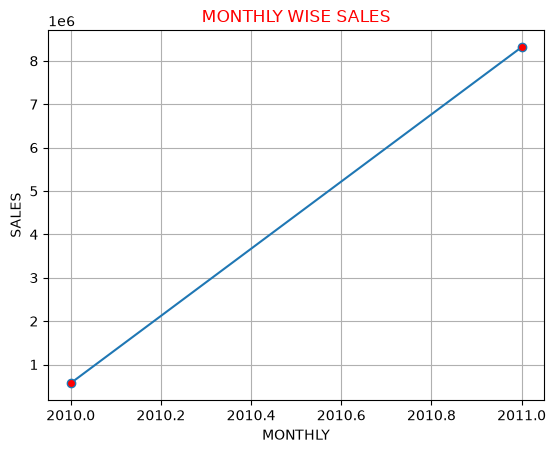

In [34]:
plt.plot(monthly_sales.index,monthly_sales.values,marker='o',markerfacecolor='red')
plt.grid()
plt.title("MONTHLY WISE SALES",color = "red")
plt.xlabel("MONTHLY")
plt.ylabel("SALES")
plt.show()

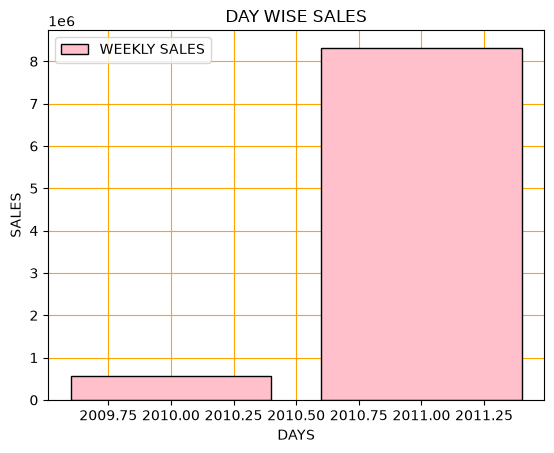

In [47]:
plt.bar(best_day.index , best_day.values , color = "pink", edgecolor = "black", label="WEEKLY SALES", zorder = 2)
plt.title("DAY WISE SALES")
plt.xlabel("DAYS")
plt.ylabel("SALES")
plt.legend()
plt.grid(color = "orange")
plt.show()

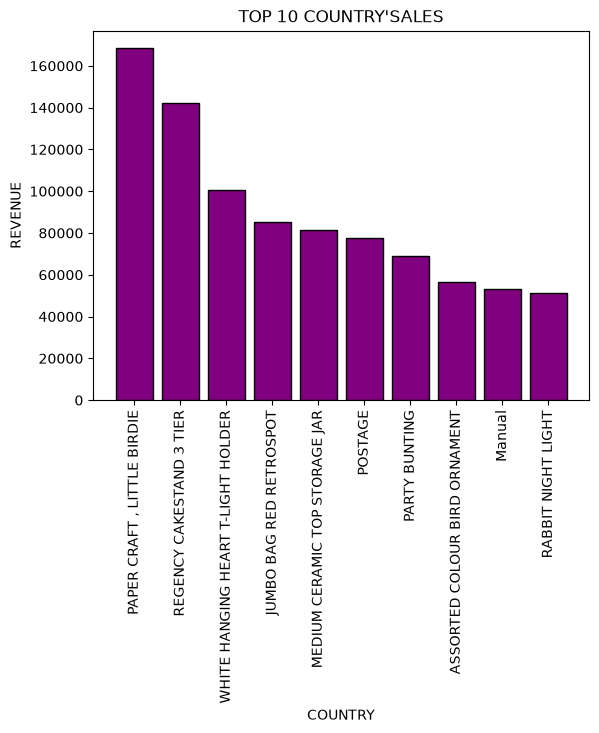

In [49]:
plt.bar(top_countries.index,top_countries.values,color = "purple",edgecolor = "black")
plt.xticks(rotation = 90)
plt.title("TOP 10 COUNTRY'SALES")
plt.xlabel("COUNTRY")
plt.ylabel("REVENUE")
plt.show()

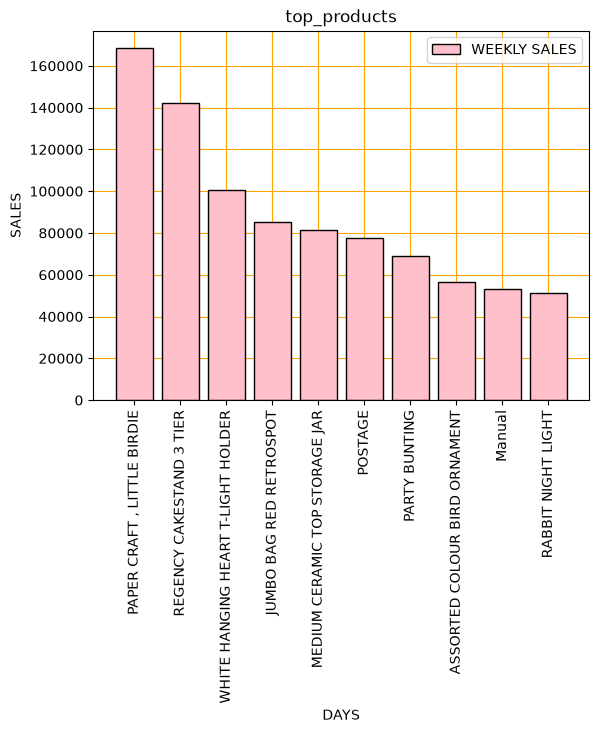

In [50]:
plt.bar(top_products.index , top_products.values , color = "pink", edgecolor = "black", label="WEEKLY SALES", zorder = 2)
plt.xticks(rotation = 90)
plt.title("top_products")
plt.xlabel("DAYS")
plt.ylabel("SALES")
plt.legend()
plt.grid(color = "orange")
plt.show()

BUSINESS INSIGTS 

In [ ]:
# United Kingdom generated highest revenue. 
# November had highest sales. Few customers contributed major revenue. 
# Certain products dominate total sales. 
# Weekend sales are higher on thrusday

In [30]:
# Best Selling Day

best_day = df.groupby('Month')['Revenue'].sum().sort_values(ascending = False)

best_day

Month
2011    8316786.164
2010     570422.730
Name: Revenue, dtype: float64